# Fase 10 — Entregable 6 (bono): fusión Sentinel-2 + SAR  (Kaggle · 2 GPUs)

**Pregunta:** ¿cuánto cambia el IoU si a la U-Net le damos también el óptico Sentinel-2 del mismo evento?

| Modo | Entrada | Canales | Para qué |
|---|---|---|---|
| `sar` | VV, VH | 2 | referencia (**re-entrenada aquí** con la misma máscara que los otros dos) |
| `optico` | B2, B3, B4, B8, B11, B12 | 6 | ¿cuánto resuelve el óptico solo? |
| `sar_optico` | VV, VH + las 6 bandas | 8 | **fusión temprana** (concatenar canales) |

**Por qué estas bandas:** visible + NIR (B8) + SWIR (B11, B12). El agua absorbe casi todo en NIR y SWIR; con ellas
están el NDWI (B3, B8) y el MNDWI (B3, B11), así que la red tiene la información de los índices clásicos.

**Rigor (igual que las ablaciones):**
- Misma U-Net (32 canales, profundidad 4, saltos), pérdida **combinada**, 60 épocas máx., paciencia 15, **3 semillas**.
- **Máscara común:** un píxel se ignora si el SAR no es finito **o** el S2 no es válido → los 3 modos se evalúan sobre los mismos píxeles. Por eso `sar` se re-entrena aquí (su IoU puede diferir un poco del 0.669 de la fase 7).
- Selección por **valid**, reporte en **test** y **Bolivia** (umbral 0.5 fijo).
- Normalización S2 calculada **solo con train** (p1/p99 + estandarización, como el SAR).
- **Δ pareado por semilla:** misma semilla = mismos lotes y aumentos → la diferencia se debe a la entrada.

**Limitación que va al informe:** el S2 de Sen1Floods11 es del **mismo día** que el S1 y los etiquetadores lo usaron para
etiquetar → el óptico tiene ventaja estructural sobre estas etiquetas. Y en un evento real con nubes, el óptico no siempre existe.

**Kaggle:** *GPU T4 x2* + *Internet On* → **Save Version → Save & Run All (Commit)**. Tiempo estimado **~35–45 min**.

## 0. Dependencias, GPUs y disco

In [1]:
!pip install -q rasterio google-cloud-storage
!nvidia-smi --query-gpu=index,name,memory.total --format=csv
!df -h /tmp | tail -1
!free -g | head -2

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB
overlay         8.0T  7.0T  1.1T  88% /
               total        used        free      shared  buff/cache   available
Mem:              31           1          25           0           5          29


## 1. Módulos de `src/` (autocontenido; 5 nuevos: `fusion_optica`, `tarea_e6`, `paralelo_e6`, `comparacion_fusion`, `visualizacion_fusion`)

In [2]:
from pathlib import Path
(Path('/kaggle/working/rnap_p2_inundaciones') / 'src').mkdir(parents=True, exist_ok=True)
(Path('/kaggle/working/rnap_p2_inundaciones') / 'src' / '__init__.py').touch()

In [3]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/configuracion.py
"""
configuracion.py  (VERSIÓN KAGGLE)
Mismas constantes que la versión de Colab; solo cambian las rutas raíz.
  - /kaggle/working  -> se guarda como "Output" del notebook al terminar (resultados, checkpoints, figuras)
  - /tmp             -> disco temporal para los datos (no infla el Output)
"""
from pathlib import Path

RAIZ_PROYECTO = Path("/kaggle/working/rnap_p2_inundaciones")
RAIZ_DATOS = Path("/tmp/datos_sen1floods11")
BUCKET = "gs://sen1floods11/v1.1"

DIR_S1_MANO        = RAIZ_DATOS / "HandLabeled" / "S1Hand"
DIR_ETIQUETA_MANO  = RAIZ_DATOS / "HandLabeled" / "LabelHand"
DIR_OTSU_MANO      = RAIZ_DATOS / "HandLabeled" / "S1OtsuLabelHand"
DIR_S2_MANO        = RAIZ_DATOS / "HandLabeled" / "S2Hand"
DIR_S1_DEBIL       = RAIZ_DATOS / "WeaklyLabeled" / "S1Weak"
DIR_ETIQUETA_DEBIL = RAIZ_DATOS / "WeaklyLabeled" / "S1OtsuLabelWeak"
DIR_PARTICIONES    = RAIZ_DATOS / "splits" / "flood_handlabeled"

DIR_RESULTADOS  = RAIZ_PROYECTO / "resultados"
DIR_CHECKPOINTS = RAIZ_PROYECTO / "checkpoints"
DIR_FIGURAS     = RAIZ_PROYECTO / "figuras"

VALOR_SIN_DATO = -1
TAMANO_CHIP = 512
SEMILLA = 42


Writing /kaggle/working/rnap_p2_inundaciones/src/configuracion.py


In [4]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/utilidades.py
"""
utilidades.py
Funciones transversales: reproducibilidad y dispositivo.
"""
import os
import random

import numpy as np
import torch


def fijar_semilla(semilla: int = 42) -> None:
    """Fija todas las fuentes de aleatoriedad para que los experimentos sean repetibles
    (clave en el estudio de ablación: si cambia el resultado, que sea por la decisión, no por azar)."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)
    os.environ["PYTHONHASHSEED"] = str(semilla)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def obtener_dispositivo() -> torch.device:
    dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if dispositivo.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    else:
        print("OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU")
    return dispositivo


Writing /kaggle/working/rnap_p2_inundaciones/src/utilidades.py


In [5]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/descarga.py
"""
descarga.py  (VERSIÓN KAGGLE)
Kaggle no trae gsutil: se usa el cliente Python de Google Cloud Storage en modo ANÓNIMO
(el bucket es público) y se descarga en paralelo con hilos.
"""
from concurrent.futures import ThreadPoolExecutor

from google.cloud import storage
from tqdm.auto import tqdm

from .configuracion import (DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO, DIR_S2_MANO,
                            DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL, DIR_PARTICIONES)

NOMBRE_BUCKET, VERSION = "sen1floods11", "v1.1"
_ORIGENES = {
    DIR_S1_MANO:        "data/flood_events/HandLabeled/S1Hand",
    DIR_ETIQUETA_MANO:  "data/flood_events/HandLabeled/LabelHand",
    DIR_OTSU_MANO:      "data/flood_events/HandLabeled/S1OtsuLabelHand",
    DIR_PARTICIONES:    "splits/flood_handlabeled",
    DIR_S2_MANO:        "data/flood_events/HandLabeled/S2Hand",
    DIR_S1_DEBIL:       "data/flood_events/WeaklyLabeled/S1Weak",
    DIR_ETIQUETA_DEBIL: "data/flood_events/WeaklyLabeled/S1OtsuLabelWeak",
}


def _descargar(destino, hilos: int = 16) -> None:
    if destino.exists() and any(destino.iterdir()):
        print(f"[ya existe] {destino.name}")
        return
    destino.mkdir(parents=True, exist_ok=True)
    cliente = storage.Client.create_anonymous_client()
    prefijo = f"{VERSION}/{_ORIGENES[destino]}/"
    blobs = [b for b in cliente.list_blobs(NOMBRE_BUCKET, prefix=prefijo) if not b.name.endswith("/")]

    def bajar(blob):
        blob.download_to_filename(str(destino / blob.name.split("/")[-1]))

    with ThreadPoolExecutor(hilos) as ejecutor:
        list(tqdm(ejecutor.map(bajar, blobs), total=len(blobs), desc=destino.name))


def descargar_mano() -> None:
    for destino in [DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO, DIR_PARTICIONES]:
        _descargar(destino)


def descargar_debil() -> None:
    for destino in [DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL]:
        _descargar(destino)


def descargar_s2_mano() -> None:
    _descargar(DIR_S2_MANO)


Writing /kaggle/working/rnap_p2_inundaciones/src/descarga.py


In [6]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/lectura.py
"""
lectura.py
Lectura de particiones y de chips GeoTIFF de Sen1Floods11.
Convención de nombres: {Evento}_{idChip}_{Capa}.tif   ej. Bolivia_103757_S1Hand.tif
"""
import numpy as np
import pandas as pd
import rasterio

from .configuracion import DIR_PARTICIONES, DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO

PARTICIONES = ["train", "valid", "test", "bolivia"]


def leer_particion(nombre: str) -> pd.DataFrame:
    """Devuelve un DataFrame con id_chip, evento y partición a partir del CSV oficial."""
    ruta = DIR_PARTICIONES / f"flood_{nombre}_data.csv"
    df = pd.read_csv(ruta, header=None, names=["archivo_s1", "archivo_etiqueta"])
    df["id_chip"] = df["archivo_s1"].str.replace("_S1Hand.tif", "", regex=False)
    df["evento"] = df["id_chip"].str.split("_").str[0]
    df["particion"] = nombre
    return df[["id_chip", "evento", "particion"]]


def leer_todas_las_particiones() -> pd.DataFrame:
    return pd.concat([leer_particion(p) for p in PARTICIONES], ignore_index=True)


def leer_tif(ruta) -> np.ndarray:
    with rasterio.open(ruta) as src:
        return src.read()          # (bandas, alto, ancho)


def leer_s1(id_chip: str, carpeta=DIR_S1_MANO, sufijo: str = "S1Hand") -> np.ndarray:
    """SAR Sentinel-1: (2, 512, 512) float32 -> banda 0 = VV, banda 1 = VH, en dB."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif").astype(np.float32)


def leer_etiqueta(id_chip: str, carpeta=DIR_ETIQUETA_MANO, sufijo: str = "LabelHand") -> np.ndarray:
    """Máscara (512, 512) int16: -1 sin dato, 0 no agua, 1 agua."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif")[0].astype(np.int16)


def leer_otsu(id_chip: str) -> np.ndarray:
    """Etiqueta automática por umbral de Otsu sobre el MISMO chip (la 'etiqueta débil')."""
    return leer_etiqueta(id_chip, DIR_OTSU_MANO, "S1OtsuLabelHand")


Writing /kaggle/working/rnap_p2_inundaciones/src/lectura.py


In [7]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/metricas.py
"""
metricas.py
Métricas de segmentación binaria para la clase "agua" a partir de conteos de la matriz de confusión.
Siempre se calculan SOLO sobre píxeles válidos (etiqueta != -1).
"""
import numpy as np


def conteos_confusion(prediccion: np.ndarray, referencia: np.ndarray, validos: np.ndarray) -> dict:
    """prediccion/referencia: arrays binarios {0,1}; validos: máscara booleana."""
    p = prediccion[validos].astype(bool)
    r = referencia[validos].astype(bool)
    return {
        "vp": int(np.sum(p & r)),     # verdaderos positivos (agua bien detectada)
        "fp": int(np.sum(p & ~r)),    # falsos positivos (dice agua y no es)
        "fn": int(np.sum(~p & r)),    # falsos negativos (agua no detectada)
        "vn": int(np.sum(~p & ~r)),   # verdaderos negativos
    }


def metricas_desde_conteos(vp: int, fp: int, fn: int, vn: int) -> dict:
    eps = 1e-9
    precision = vp / (vp + fp + eps)
    recall = vp / (vp + fn + eps)
    return {
        "iou": vp / (vp + fp + fn + eps),
        "f1": 2 * precision * recall / (precision + recall + eps),
        "precision": precision,
        "recall": recall,
        "omision": fn / (vp + fn + eps),     # = 1 - recall   (agua que se nos escapó)
        "comision": fp / (vp + fp + eps),    # = 1 - precision (agua inventada)
        "exactitud": (vp + vn) / (vp + fp + fn + vn + eps),
    }


Writing /kaggle/working/rnap_p2_inundaciones/src/metricas.py


In [8]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/metricas_torch.py
"""
metricas_torch.py
Acumulador de la matriz de confusión durante la evaluación (en GPU, sin copiar píxeles a CPU).
Clave: las métricas se calculan con los conteos SUMADOS de todos los chips (IoU agregado),
no promediando IoU chip por chip -> los chips sin agua (26 en Ghana) no producen 0/0.
También acumula por evento, para el desglose del informe.
"""
from collections import defaultdict

import numpy as np
import pandas as pd
import torch

from .metricas import metricas_desde_conteos

VALOR_IGNORAR = -1


class AcumuladorConfusion:
    def __init__(self, umbral: float = 0.5):
        self.umbral = umbral
        self.reiniciar()

    def reiniciar(self):
        self.global_ = torch.zeros(4, dtype=torch.int64)           # vp, fp, fn, vn
        self.por_evento = defaultdict(lambda: torch.zeros(4, dtype=torch.int64))

    @torch.no_grad()
    def actualizar(self, logits, etiquetas, ids_chips=None):
        if logits.dim() == 4:
            logits = logits.squeeze(1)
        prediccion = torch.sigmoid(logits.float()) > self.umbral
        referencia = etiquetas == 1
        validos = etiquetas != VALOR_IGNORAR
        # conteos por chip (dim 1,2 = alto, ancho) -> (B, 4)
        conteos = torch.stack([
            (prediccion & referencia & validos).sum(dim=(1, 2)),
            (prediccion & ~referencia & validos).sum(dim=(1, 2)),
            (~prediccion & referencia & validos).sum(dim=(1, 2)),
            (~prediccion & ~referencia & validos).sum(dim=(1, 2)),
        ], dim=1).cpu()
        self.global_ += conteos.sum(dim=0)
        if ids_chips is not None:
            for id_chip, fila in zip(ids_chips, conteos):
                self.por_evento[id_chip.split("_")[0]] += fila

    def metricas(self) -> dict:
        return metricas_desde_conteos(*self.global_.tolist())

    def matriz_confusion(self) -> np.ndarray:
        """[[VN, FP], [FN, VP]]  (filas = real no agua / agua; columnas = predicho no agua / agua)."""
        vp, fp, fn, vn = self.global_.tolist()
        return np.array([[vn, fp], [fn, vp]], dtype=np.int64)

    def tabla_por_evento(self) -> pd.DataFrame:
        filas = {evento: metricas_desde_conteos(*c.tolist()) for evento, c in self.por_evento.items()}
        return pd.DataFrame(filas).T.sort_values("iou")


Writing /kaggle/working/rnap_p2_inundaciones/src/metricas_torch.py


In [9]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/preprocesamiento.py
"""
preprocesamiento.py
Normalización de las bandas SAR (VV, VH) con las estadísticas calculadas SOLO en train (fase 1).
Pasos:  1) detectar píxeles no finitos (NaN/inf)
        2) recortar a [p1, p99]  -> evita que valores extremos dominen
        3) estandarizar (x - media) / desviacion  -> entradas centradas en 0 y escala ~1
        4) NaN -> 0 (que tras estandarizar = "valor medio": la red no recibe basura)
"""
import json

import numpy as np

BANDAS = ["vv", "vh"]


class Normalizador:
    def __init__(self, estadisticas: dict):
        self.minimos = np.array([estadisticas[b]["p1"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.maximos = np.array([estadisticas[b]["p99"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.medias = np.array([estadisticas[b]["media"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.desviaciones = np.array([estadisticas[b]["desviacion"] for b in BANDAS], dtype=np.float32)[:, None, None]

    @classmethod
    def desde_json(cls, ruta) -> "Normalizador":
        with open(ruta) as f:
            return cls(json.load(f))

    def __call__(self, s1: np.ndarray):
        """s1: (2, H, W) en dB -> (s1 normalizado (2, H, W), máscara de píxeles finitos (H, W))."""
        finitos = np.isfinite(s1).all(axis=0)
        x = np.clip(s1, self.minimos, self.maximos)
        x = (x - self.medias) / self.desviaciones
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        return x.astype(np.float32), finitos

    def revertir(self, x: np.ndarray) -> np.ndarray:
        """De vuelta a dB (útil para visualizar lo que entra a la red)."""
        return x * self.desviaciones + self.medias


Writing /kaggle/working/rnap_p2_inundaciones/src/preprocesamiento.py


In [10]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/aumentos.py
"""
aumentos.py
Aumento de datos geométrico. Regla de oro en segmentación: la MISMA transformación
a la imagen y a la máscara, si no la etiqueta deja de corresponder al píxel.

Solo usamos volteos y rotaciones de 90°: no inventan valores (no hay interpolación),
así que la máscara sigue siendo exactamente {-1, 0, 1}.
Matiz para el informe: el SAR mira de lado (geometría oblicua), por lo que la dirección
de sombras/layover no es invariante a rotaciones; aun así es la práctica estándar
y mejora la generalización con pocos datos (446 chips).
"""
import numpy as np


def aumentar(imagen: np.ndarray, etiqueta: np.ndarray, generador: np.random.Generator):
    """imagen: (C, H, W); etiqueta: (H, W)."""
    if generador.random() < 0.5:                       # volteo horizontal
        imagen, etiqueta = imagen[:, :, ::-1], etiqueta[:, ::-1]
    if generador.random() < 0.5:                       # volteo vertical
        imagen, etiqueta = imagen[:, ::-1, :], etiqueta[::-1, :]
    k = int(generador.integers(0, 4))                  # rotación 0/90/180/270
    if k:
        imagen = np.rot90(imagen, k, axes=(1, 2))
        etiqueta = np.rot90(etiqueta, k, axes=(0, 1))
    return np.ascontiguousarray(imagen), np.ascontiguousarray(etiqueta)


def recorte_aleatorio(imagen: np.ndarray, etiqueta: np.ndarray, tamano: int, generador: np.random.Generator):
    """Recorta una ventana tamano x tamano en posición aleatoria (otra forma de aumento)."""
    _, alto, ancho = imagen.shape
    fila = int(generador.integers(0, alto - tamano + 1))
    columna = int(generador.integers(0, ancho - tamano + 1))
    return (imagen[:, fila:fila + tamano, columna:columna + tamano],
            etiqueta[fila:fila + tamano, columna:columna + tamano])


Writing /kaggle/working/rnap_p2_inundaciones/src/aumentos.py


In [11]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/conjunto_datos.py
"""
conjunto_datos.py
Dataset de PyTorch para Sen1Floods11.
Devuelve (imagen, etiqueta, id_chip):
  imagen   : tensor float32 (2, H, W)  -> VV, VH normalizados
  etiqueta : tensor int64   (H, W)     -> 0 no agua, 1 agua, -1 IGNORAR (sin dato o SAR no finito)
"""
import numpy as np
import torch
from torch.utils.data import Dataset
from tqdm.auto import tqdm

from .aumentos import aumentar, recorte_aleatorio
from .configuracion import VALOR_SIN_DATO, DIR_S1_MANO, DIR_ETIQUETA_MANO
from .lectura import leer_s1, leer_etiqueta


class ConjuntoInundaciones(Dataset):
    def __init__(self, ids_chips, normalizador, aumentar_datos: bool = False,
                 tamano_recorte: int | None = None, en_memoria: bool = True,
                 dir_s1=DIR_S1_MANO, sufijo_s1: str = "S1Hand",
                 dir_etiqueta=DIR_ETIQUETA_MANO, sufijo_etiqueta: str = "LabelHand",
                 semilla: int = 42):
        self.ids_chips = list(ids_chips)
        self.normalizador = normalizador
        self.aumentar_datos = aumentar_datos
        self.tamano_recorte = tamano_recorte
        self.dir_s1, self.sufijo_s1 = dir_s1, sufijo_s1
        self.dir_etiqueta, self.sufijo_etiqueta = dir_etiqueta, sufijo_etiqueta
        self.generador = np.random.default_rng(semilla)

        # Los chips a mano caben en RAM (~2 MB c/u): se cargan UNA vez, antes de que los
        # workers del DataLoader se creen (así lo comparten en vez de leer disco cada época).
        self.cache = None
        if en_memoria:
            self.cache = [self._cargar(i) for i in tqdm(self.ids_chips, desc="Cargando chips en RAM")]

    def _cargar(self, id_chip):
        s1 = leer_s1(id_chip, self.dir_s1, self.sufijo_s1)
        etiqueta = leer_etiqueta(id_chip, self.dir_etiqueta, self.sufijo_etiqueta)
        imagen, finitos = self.normalizador(s1)
        etiqueta = etiqueta.copy()
        etiqueta[~finitos] = VALOR_SIN_DATO          # SAR inválido -> no se evalúa ni se aprende
        return imagen, etiqueta.astype(np.int64)

    def __len__(self):
        return len(self.ids_chips)

    def __getitem__(self, indice):
        imagen, etiqueta = self.cache[indice] if self.cache is not None else self._cargar(self.ids_chips[indice])
        if self.tamano_recorte:
            imagen, etiqueta = recorte_aleatorio(imagen, etiqueta, self.tamano_recorte, self.generador)
        if self.aumentar_datos:
            imagen, etiqueta = aumentar(imagen, etiqueta, self.generador)
        return torch.from_numpy(np.ascontiguousarray(imagen)), \
               torch.from_numpy(np.ascontiguousarray(etiqueta)), self.ids_chips[indice]


def semilla_por_worker(id_worker: int):
    """Cada worker del DataLoader recibe su propio generador (si no, todos aumentarían igual)."""
    informacion = torch.utils.data.get_worker_info()
    semilla = (torch.initial_seed() + id_worker) % 2**32
    informacion.dataset.generador = np.random.default_rng(semilla)


Writing /kaggle/working/rnap_p2_inundaciones/src/conjunto_datos.py


In [12]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/cargadores.py
"""
cargadores.py
Crea los DataLoader de las 4 particiones oficiales de los chips a mano.
Solo 'train' lleva aumento de datos (y recorte opcional); valid/test/bolivia se evalúan tal cual.
"""
import torch
from torch.utils.data import DataLoader

from .conjunto_datos import ConjuntoInundaciones, semilla_por_worker
from .lectura import leer_particion


def crear_cargadores(normalizador, tamano_lote: int = 8, tamano_recorte: int | None = None,
                     num_workers: int = 2, semilla: int = 42) -> dict:
    cargadores = {}
    for particion in ["train", "valid", "test", "bolivia"]:
        es_train = particion == "train"
        ids = leer_particion(particion)["id_chip"]
        conjunto = ConjuntoInundaciones(ids, normalizador, aumentar_datos=es_train,
                                        tamano_recorte=tamano_recorte if es_train else None,
                                        semilla=semilla)
        cargadores[particion] = DataLoader(
            conjunto,
            batch_size=tamano_lote if es_train else max(1, tamano_lote // 2),
            shuffle=es_train,
            drop_last=es_train,              # evita un último lote de 1-2 chips (BatchNorm inestable)
            num_workers=num_workers,
            pin_memory=torch.cuda.is_available(),
            worker_init_fn=semilla_por_worker,
            generator=torch.Generator().manual_seed(semilla),
            persistent_workers=num_workers > 0,
        )
        print(f"{particion:8s}: {len(conjunto):3d} chips -> {len(cargadores[particion]):3d} lotes")
    return cargadores


Writing /kaggle/working/rnap_p2_inundaciones/src/cargadores.py


In [13]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/modelo_unet.py
"""
modelo_unet.py
U-Net implementada desde cero (Ronneberger et al., 2015), adaptada a SAR de 2 bandas.

Arquitectura (profundidad=4, canales_base=c):
  Entrada (2, H, W)
  ├─ Codificador  : DobleConv(2→c) → [MaxPool + DobleConv] x4  (c→2c→4c→8c→16c)   "qué hay"
  ├─ Decodificador: [ConvTranspuesta ×2 + concatenar salto + DobleConv] x4         "dónde está"
  └─ Cabeza 1x1   : c → 1 canal = logit de "agua" por píxel

Diferencias con el paper original (documentarlas en el informe):
  - padding=1 ("same"): la salida tiene el mismo tamaño que la entrada (el original recortaba).
  - BatchNorm tras cada convolución (no existía en 2015; estabiliza y acelera el entrenamiento).
  - 1 canal de salida con sigmoide (problema binario) en vez de 2 con softmax.
  - Parámetros configurables para la ablación: profundidad, canales_base y usar_saltos.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class DobleConv(nn.Module):
    """(Conv 3x3 → BatchNorm → ReLU) x 2. Bloque básico de la U-Net."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        capas = [
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
            nn.Conv2d(canales_salida, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
        ]
        if abandono > 0:
            capas.append(nn.Dropout2d(abandono))
        self.bloque = nn.Sequential(*capas)

    def forward(self, x):
        return self.bloque(x)


class Bajada(nn.Module):
    """MaxPool 2x2 (reduce resolución a la mitad) + DobleConv (duplica canales)."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        self.agrupar = nn.MaxPool2d(2)
        self.conv = DobleConv(canales_entrada, canales_salida, abandono)

    def forward(self, x):
        return self.conv(self.agrupar(x))


class Subida(nn.Module):
    """ConvTranspuesta 2x2 (duplica resolución) + concatenar el salto del codificador + DobleConv."""

    def __init__(self, canales_entrada: int, canales_salida: int, usar_salto: bool = True):
        super().__init__()
        self.usar_salto = usar_salto
        self.subir = nn.ConvTranspose2d(canales_entrada, canales_entrada // 2, kernel_size=2, stride=2)
        canales_conv = canales_entrada // 2 + (canales_salida if usar_salto else 0)
        self.conv = DobleConv(canales_conv, canales_salida)

    def forward(self, x, salto):
        x = self.subir(x)
        # si H o W no eran divisibles entre 2^profundidad, ajustamos con padding al tamaño del salto
        dif_alto, dif_ancho = salto.shape[2] - x.shape[2], salto.shape[3] - x.shape[3]
        if dif_alto or dif_ancho:
            x = F.pad(x, [dif_ancho // 2, dif_ancho - dif_ancho // 2, dif_alto // 2, dif_alto - dif_alto // 2])
        if self.usar_salto:
            x = torch.cat([salto, x], dim=1)   # detalle espacial fino (salto) + contexto (x)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, canales_entrada: int = 2, canales_base: int = 32, profundidad: int = 4,
                 usar_saltos: bool = True, abandono: float = 0.0):
        super().__init__()
        self.configuracion = dict(canales_entrada=canales_entrada, canales_base=canales_base,
                                  profundidad=profundidad, usar_saltos=usar_saltos, abandono=abandono)
        canales = [canales_base * 2 ** i for i in range(profundidad + 1)]   # ej. 32, 64, 128, 256, 512

        self.entrada = DobleConv(canales_entrada, canales[0])
        # el abandono (dropout) solo en los niveles más profundos, donde hay más parámetros
        self.codificador = nn.ModuleList(
            Bajada(canales[i], canales[i + 1], abandono if i >= profundidad - 2 else 0.0)
            for i in range(profundidad)
        )
        self.decodificador = nn.ModuleList(
            Subida(canales[i + 1], canales[i], usar_saltos) for i in reversed(range(profundidad))
        )
        self.salida = nn.Conv2d(canales[0], 1, kernel_size=1)
        self._inicializar_pesos()

    def _inicializar_pesos(self):
        """He/Kaiming: pensada para ReLU, mantiene la varianza de las activaciones entre capas."""
        for modulo in self.modules():
            if isinstance(modulo, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(modulo.weight, mode="fan_out", nonlinearity="relu")
                if modulo.bias is not None:
                    nn.init.zeros_(modulo.bias)
            elif isinstance(modulo, nn.BatchNorm2d):
                nn.init.ones_(modulo.weight)
                nn.init.zeros_(modulo.bias)

    def forward(self, x, devolver_formas: bool = False):
        formas = [("entrada", tuple(x.shape))]
        x = self.entrada(x)
        saltos = [x]
        formas.append(("codificador nivel 0", tuple(x.shape)))
        for nivel, bajada in enumerate(self.codificador, start=1):
            x = bajada(x)
            saltos.append(x)
            formas.append((f"codificador nivel {nivel}" + (" (cuello)" if nivel == len(self.codificador) else ""),
                           tuple(x.shape)))
        saltos.pop()  # el cuello de botella no es salto de nadie
        for nivel, subida in zip(reversed(range(len(saltos))), self.decodificador):
            x = subida(x, saltos.pop())
            formas.append((f"decodificador nivel {nivel}", tuple(x.shape)))
        logits = self.salida(x)
        formas.append(("salida (logits)", tuple(logits.shape)))
        return (logits, formas) if devolver_formas else logits


def contar_parametros(modelo: nn.Module) -> int:
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def campo_receptivo(modelo: nn.Module, tamano: int = 512) -> int:
    """Campo receptivo EMPÍRICO: cuántos píxeles de la entrada influyen en el píxel central de la
    salida. Se mide con el gradiente: d(salida_centro)/d(entrada) es distinto de 0 solo dentro del campo.
    Indica cuánto 'contexto' mira la red para decidir si un píxel es agua."""
    estaba_entrenando = modelo.training
    modelo.eval()
    parametro = next(modelo.parameters())
    x = torch.randn(1, modelo.configuracion["canales_entrada"], tamano, tamano,
                    device=parametro.device, requires_grad=True)
    modelo(x)[0, 0, tamano // 2, tamano // 2].backward()
    influye = (x.grad.abs().sum(dim=(0, 1)) > 0)
    filas = torch.where(influye.any(dim=1))[0]
    modelo.train(estaba_entrenando)
    return int(filas.max() - filas.min() + 1)


Writing /kaggle/working/rnap_p2_inundaciones/src/modelo_unet.py


In [14]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/perdidas.py
"""
perdidas.py
Funciones de pérdida para segmentación binaria con píxeles a IGNORAR (etiqueta = -1).
Todas reciben:
  logits    : (B, 1, H, W) o (B, H, W)  -> salida cruda de la U-Net (sin sigmoide)
  etiquetas : (B, H, W) int64           -> 0 no agua, 1 agua, -1 ignorar
Las tres opciones son las de la ablación (b): BCE vs Dice vs combinada.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

VALOR_IGNORAR = -1


def _aplanar_validos(logits, etiquetas):
    if logits.dim() == 4:
        logits = logits.squeeze(1)
    validos = etiquetas != VALOR_IGNORAR
    return logits[validos], (etiquetas[validos] == 1).float()


class PerdidaBCE(nn.Module):
    """Entropía cruzada binaria por píxel.
    + Gradientes estables y bien comportados desde el inicio.
    - Cada píxel pesa igual: con ~9 % de agua, la red puede 'ganar' prediciendo casi todo no-agua.
    peso_positivo > 1 compensa ese desbalance multiplicando el error en píxeles de agua."""

    def __init__(self, peso_positivo: float | None = None):
        super().__init__()
        self.peso_positivo = peso_positivo

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:                       # lote sin píxeles válidos: pérdida 0 sin romper el grafo
            return logits.sum() * 0.0
        peso = None if self.peso_positivo is None else torch.tensor(self.peso_positivo, device=x.device)
        return F.binary_cross_entropy_with_logits(x, y, pos_weight=peso)


class PerdidaDice(nn.Module):
    """Pérdida Dice 'suave' (Milletari et al., 2016):  1 - 2·Σ(p·y) / (Σp + Σy)
    con p = sigmoide(logits) (probabilidades continuas, para que sea derivable).
    + Mide superposición de la CLASE AGUA: el fondo abundante no la domina -> robusta al desbalance.
    - Gradientes más ruidosos, sobre todo si el lote tiene poca agua.
    Se calcula sobre TODO el lote (no chip por chip): así un chip sin agua no produce 0/0."""

    def __init__(self, suavizado: float = 1.0):
        super().__init__()
        self.suavizado = suavizado

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:
            return logits.sum() * 0.0
        p = torch.sigmoid(x.float())             # float32 aunque se entrene con AMP (sumas grandes)
        interseccion = (p * y).sum()
        return 1 - (2 * interseccion + self.suavizado) / (p.sum() + y.sum() + self.suavizado)


class PerdidaCombinada(nn.Module):
    """peso_bce · BCE + peso_dice · Dice: estabilidad de la BCE + foco en la clase minoritaria del Dice."""

    def __init__(self, peso_bce: float = 0.5, peso_dice: float = 0.5, peso_positivo: float | None = None):
        super().__init__()
        self.peso_bce, self.peso_dice = peso_bce, peso_dice
        self.bce = PerdidaBCE(peso_positivo)
        self.dice = PerdidaDice()

    def forward(self, logits, etiquetas):
        return self.peso_bce * self.bce(logits, etiquetas) + self.peso_dice * self.dice(logits, etiquetas)


def crear_perdida(nombre: str, **parametros) -> nn.Module:
    """Fábrica para la ablación: crear_perdida('bce' | 'dice' | 'combinada')."""
    opciones = {"bce": PerdidaBCE, "dice": PerdidaDice, "combinada": PerdidaCombinada}
    if nombre not in opciones:
        raise ValueError(f"Pérdida desconocida '{nombre}'. Opciones: {list(opciones)}")
    return opciones[nombre](**parametros)


Writing /kaggle/working/rnap_p2_inundaciones/src/perdidas.py


In [15]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/experimento.py
"""
experimento.py
Configuración de un experimento. Cada corrida (base y ablaciones) se describe con UNA instancia,
se guarda como JSON junto a sus resultados -> trazabilidad total para el informe.
"""
import json
from dataclasses import dataclass, asdict, field


@dataclass
class ConfiguracionExperimento:
    nombre: str = "base_bce"
    # --- datos ---
    fuente_entrenamiento: str = "mano"      # "mano" | "mano+debil" (fase 6)
    tamano_lote: int = 8
    tamano_recorte: int = 256
    # --- modelo ---
    canales_base: int = 32
    profundidad: int = 4
    usar_saltos: bool = True
    abandono: float = 0.0
    # --- pérdida ---
    perdida: str = "bce"                     # "bce" | "dice" | "combinada"
    parametros_perdida: dict = field(default_factory=dict)
    # --- optimización ---
    tasa_aprendizaje: float = 1e-3
    decaimiento_pesos: float = 1e-4          # regularización L2 desacoplada (AdamW)
    epocas: int = 100
    epocas_calentamiento: int = 3            # la tasa sube linealmente al inicio (evita saltos bruscos)
    paciencia: int = 20                      # parada temprana: épocas sin mejorar IoU de validación
    umbral: float = 0.5
    semilla: int = 42

    def guardar(self, ruta):
        with open(ruta, "w") as f:
            json.dump(asdict(self), f, indent=2, ensure_ascii=False)

    @classmethod
    def cargar(cls, ruta):
        with open(ruta) as f:
            return cls(**json.load(f))


Writing /kaggle/working/rnap_p2_inundaciones/src/experimento.py


In [16]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/evaluacion.py
"""
evaluacion.py
Evaluación de un modelo sobre un DataLoader completo (chips enteros de 512x512).
"""
import torch

from .metricas_torch import AcumuladorConfusion


@torch.no_grad()
def evaluar(modelo, cargador, dispositivo, perdida=None, umbral: float = 0.5):
    """Devuelve (acumulador con métricas globales y por evento, pérdida media o None)."""
    modelo.eval()
    acumulador = AcumuladorConfusion(umbral)
    suma_perdida, n_lotes = 0.0, 0
    usar_amp = dispositivo.type == "cuda"
    for imagenes, etiquetas, ids in cargador:
        imagenes = imagenes.to(dispositivo, non_blocking=True)
        etiquetas = etiquetas.to(dispositivo, non_blocking=True)
        with torch.autocast(dispositivo.type, dtype=torch.float16, enabled=usar_amp):
            logits = modelo(imagenes)
        acumulador.actualizar(logits, etiquetas, ids)
        if perdida is not None:
            suma_perdida += perdida(logits.float(), etiquetas).item()
            n_lotes += 1
    return acumulador, (suma_perdida / n_lotes if n_lotes else None)


@torch.no_grad()
def predecir_probabilidades(modelo, imagen, dispositivo):
    """imagen: tensor (2, H, W) -> mapa de probabilidad de agua (H, W) en CPU."""
    modelo.eval()
    logits = modelo(imagen[None].to(dispositivo))
    return torch.sigmoid(logits.float())[0, 0].cpu()


Writing /kaggle/working/rnap_p2_inundaciones/src/evaluacion.py


In [17]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/entrenamiento.py
"""
entrenamiento.py
Bucle de entrenamiento con:
  - AdamW + calentamiento lineal + decaimiento coseno de la tasa de aprendizaje
  - precisión mixta (AMP) en GPU
  - selección del mejor modelo por IoU de VALIDACIÓN (test no se mira hasta el final)
  - parada temprana
  - checkpoint en Drive en cada época -> si Colab se desconecta, se REANUDA donde quedó
"""
import json
import math
import time

import pandas as pd
import torch

from .evaluacion import evaluar
from .modelo_unet import UNet
from .perdidas import crear_perdida
from .utilidades import fijar_semilla


def crear_modelo(configuracion):
    return UNet(canales_entrada=2, canales_base=configuracion.canales_base,
                profundidad=configuracion.profundidad, usar_saltos=configuracion.usar_saltos,
                abandono=configuracion.abandono)


def _factor_tasa(epoca, configuracion):
    """Multiplicador de la tasa de aprendizaje en cada época (0-indexada)."""
    if epoca < configuracion.epocas_calentamiento:
        return (epoca + 1) / configuracion.epocas_calentamiento
    progreso = (epoca - configuracion.epocas_calentamiento) / max(1, configuracion.epocas - configuracion.epocas_calentamiento)
    return 0.5 * (1 + math.cos(math.pi * progreso))


def entrenar(configuracion, cargador_entrenamiento, cargador_validacion, dispositivo, dir_salida,
             reanudar: bool = True):
    dir_salida.mkdir(parents=True, exist_ok=True)
    configuracion.guardar(dir_salida / "configuracion.json")
    fijar_semilla(configuracion.semilla)

    modelo = crear_modelo(configuracion).to(dispositivo)
    perdida = crear_perdida(configuracion.perdida, **configuracion.parametros_perdida)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=configuracion.tasa_aprendizaje,
                                    weight_decay=configuracion.decaimiento_pesos)
    planificador = torch.optim.lr_scheduler.LambdaLR(optimizador, lambda e: _factor_tasa(e, configuracion))
    usar_amp = dispositivo.type == "cuda"
    escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)

    epoca_inicial, mejor_iou, epocas_sin_mejora, historial = 0, -1.0, 0, []
    ruta_ultimo, ruta_mejor = dir_salida / "ultimo.pt", dir_salida / "mejor.pt"
    if reanudar and ruta_ultimo.exists():
        estado = torch.load(ruta_ultimo, map_location=dispositivo, weights_only=False)
        modelo.load_state_dict(estado["modelo"]); optimizador.load_state_dict(estado["optimizador"])
        planificador.load_state_dict(estado["planificador"]); escalador.load_state_dict(estado["escalador"])
        epoca_inicial, mejor_iou = estado["epoca"] + 1, estado["mejor_iou"]
        epocas_sin_mejora, historial = estado["epocas_sin_mejora"], estado["historial"]
        print(f"↻ Reanudando desde la época {epoca_inicial} (mejor IoU valid = {mejor_iou:.4f})")

    for epoca in range(epoca_inicial, configuracion.epocas):
        inicio = time.time()
        modelo.train()
        suma_perdida, n_lotes = 0.0, 0
        for imagenes, etiquetas, _ in cargador_entrenamiento:
            imagenes = imagenes.to(dispositivo, non_blocking=True)
            etiquetas = etiquetas.to(dispositivo, non_blocking=True)
            with torch.autocast(dispositivo.type, dtype=torch.float16, enabled=usar_amp):
                logits = modelo(imagenes)
            valor = perdida(logits.float(), etiquetas)   # la pérdida siempre en float32 (más estable)
            optimizador.zero_grad(set_to_none=True)
            escalador.scale(valor).backward()
            escalador.step(optimizador)
            escalador.update()
            suma_perdida += valor.item(); n_lotes += 1
        planificador.step()

        acumulador, perdida_valid = evaluar(modelo, cargador_validacion, dispositivo, perdida, configuracion.umbral)
        m = acumulador.metricas()
        fila = {"epoca": epoca + 1, "tasa": optimizador.param_groups[0]["lr"],
                "perdida_train": suma_perdida / max(n_lotes, 1), "perdida_valid": perdida_valid,
                **{f"{k}_valid": v for k, v in m.items()}, "segundos": time.time() - inicio}
        historial.append(fila)

        mejoro = m["iou"] > mejor_iou
        if mejoro:
            mejor_iou, epocas_sin_mejora = m["iou"], 0
            torch.save({"modelo": modelo.state_dict(), "epoca": epoca + 1, "iou_valid": mejor_iou,
                        "configuracion": configuracion.__dict__}, ruta_mejor)
        else:
            epocas_sin_mejora += 1
        torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                    "planificador": planificador.state_dict(), "escalador": escalador.state_dict(),
                    "epoca": epoca, "mejor_iou": mejor_iou, "epocas_sin_mejora": epocas_sin_mejora,
                    "historial": historial}, ruta_ultimo)
        pd.DataFrame(historial).to_csv(dir_salida / "historial.csv", index=False)

        print(f"época {epoca + 1:3d} | pérdida train {fila['perdida_train']:.4f} valid {perdida_valid:.4f} | "
              f"IoU valid {m['iou']:.4f} | F1 {m['f1']:.4f} | {fila['segundos']:.0f}s" + ("  ★" if mejoro else ""))
        if epocas_sin_mejora >= configuracion.paciencia:
            print(f"Parada temprana: {configuracion.paciencia} épocas sin mejorar.")
            break

    resumen = {"nombre": configuracion.nombre, "mejor_iou_valid": mejor_iou,
               "mejor_epoca": int(pd.DataFrame(historial)["iou_valid"].idxmax()) + 1,
               "epocas_entrenadas": len(historial)}
    with open(dir_salida / "resumen.json", "w") as f:
        json.dump(resumen, f, indent=2)
    return pd.DataFrame(historial), resumen


def cargar_mejor_modelo(dir_salida, dispositivo):
    from .experimento import ConfiguracionExperimento
    configuracion = ConfiguracionExperimento.cargar(dir_salida / "configuracion.json")
    modelo = crear_modelo(configuracion).to(dispositivo)
    estado = torch.load(dir_salida / "mejor.pt", map_location=dispositivo, weights_only=False)
    modelo.load_state_dict(estado["modelo"])
    modelo.eval()
    return modelo, configuracion, estado["epoca"]


Writing /kaggle/working/rnap_p2_inundaciones/src/entrenamiento.py


In [18]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/visualizacion_final.py
"""
visualizacion_final.py
Mapa de errores por píxel y curva IoU-umbral (fase 7; también se reutiliza en el análisis de fallos).
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# 0 ignorado, 1 VN, 2 VP, 3 FP (agua inventada), 4 FN (agua perdida)
MAPA_ERRORES = ListedColormap(["#ffffff", "#e8e3d6", "#1f5fbf", "#d62728", "#ff9f1c"])
LEYENDA = [Patch(color=c, label=t) for c, t in zip(MAPA_ERRORES.colors[1:], ["VN", "VP", "FP (comisión)", "FN (omisión)"])]


def mapa_errores(etiqueta, probabilidad, umbral=0.5):
    prediccion = probabilidad > umbral
    mapa = np.zeros(etiqueta.shape, dtype=np.int8)
    validos = etiqueta != -1
    mapa[validos & ~prediccion & (etiqueta == 0)] = 1
    mapa[validos & prediccion & (etiqueta == 1)] = 2
    mapa[validos & prediccion & (etiqueta == 0)] = 3
    mapa[validos & ~prediccion & (etiqueta == 1)] = 4
    return mapa


def figura_errores(ejemplos, umbral=0.5, ruta_guardado=None):
    """ejemplos: [(id_chip, vh_normalizado, etiqueta, probabilidad), ...] -> VH | P(agua) | mapa de errores."""
    figura, ejes = plt.subplots(len(ejemplos), 3, figsize=(10, 3.3 * len(ejemplos)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, vh, etiqueta, probabilidad) in enumerate(ejemplos):
        ejes[fila, 0].imshow(vh, cmap="gray", vmin=-2.5, vmax=2.5); ejes[fila, 0].set_title(f"{id_chip} — VH", fontsize=9)
        ejes[fila, 1].imshow(probabilidad, cmap="Blues", vmin=0, vmax=1); ejes[fila, 1].set_title("P(agua)", fontsize=9)
        ejes[fila, 2].imshow(mapa_errores(etiqueta, probabilidad, umbral), cmap=MAPA_ERRORES, vmin=0, vmax=4,
                             interpolation="nearest")
        ejes[fila, 2].set_title("Errores", fontsize=9)
        for eje in ejes[fila]:
            eje.axis("off")
    figura.legend(handles=LEYENDA, loc="lower center", ncol=4, frameon=False)
    figura.tight_layout(rect=(0, 0.03, 1, 1))
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def figura_curva_umbral(curvas_valid, curvas_test, ruta_guardado=None):
    figura, eje = plt.subplots(figsize=(6.5, 4))
    for semilla in curvas_valid:
        eje.plot(curvas_valid[semilla]["umbral"], curvas_valid[semilla]["iou"], color="#7a9cc6", alpha=0.8,
                 label="valid" if semilla == list(curvas_valid)[0] else None)
        eje.plot(curvas_test[semilla]["umbral"], curvas_test[semilla]["iou"], color="#1f5fbf",
                 label="test" if semilla == list(curvas_valid)[0] else None)
    eje.axvline(0.5, ls="--", color="gray", label="umbral 0.5")
    eje.set_xlabel("Umbral sobre P(agua)"); eje.set_ylabel("IoU agua"); eje.set_title("IoU vs. umbral (una línea por semilla)")
    eje.legend(); eje.grid(alpha=0.3)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /kaggle/working/rnap_p2_inundaciones/src/visualizacion_final.py


In [19]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/paralelo_6a.py
"""
paralelo_6a.py
Reparte las corridas de la ablación (a) entre varias GPUs: UN PROCESO POR GPU, cada uno con su
propia lista de tareas (paralelismo por experimentos). Las corridas son independientes, así que
los resultados son idénticos a correrlas en serie, pero el tiempo total se reduce.

Reparto: algoritmo voraz LPT (la tarea más larga a la GPU menos cargada), con duraciones estimadas.
"""
import json
import os
import subprocess
import sys
import time
from collections import deque

import pandas as pd

# minutos estimados en una T4 (solo para balancear la carga, no tienen que ser exactos)
DURACION_ESTIMADA = {"combinada": 5, "debil": 30}


def armar_plan(semillas, n_gpus, configuracion_base, parametros, ruta_plan):
    tareas = [f"combinada:{s}" for s in semillas] + [f"debil:{s}" for s in semillas]
    tareas.sort(key=lambda t: DURACION_ESTIMADA[t.split(":")[0]], reverse=True)
    cargas, asignacion = [0] * n_gpus, {str(g): [] for g in range(n_gpus)}
    for tarea in tareas:
        gpu = cargas.index(min(cargas))
        asignacion[str(gpu)].append(tarea)
        cargas[gpu] += DURACION_ESTIMADA[tarea.split(":")[0]]
    plan = {"tareas_por_gpu": asignacion, "configuracion_base": configuracion_base.__dict__, "parametros": parametros}
    with open(ruta_plan, "w") as f:
        json.dump(plan, f, indent=2)
    for gpu, lista in asignacion.items():
        print(f"GPU {gpu}: {lista}  (~{cargas[int(gpu)]} min estimados)")
    return plan


def lanzar(ruta_plan, n_gpus, raiz_proyecto, dir_logs):
    dir_logs.mkdir(parents=True, exist_ok=True)
    procesos = []
    for gpu in range(n_gpus):
        entorno = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTHONUNBUFFERED="1")
        log = open(dir_logs / f"gpu{gpu}.log", "w")
        proceso = subprocess.Popen([sys.executable, "-m", "src.tarea_6a", "--plan", str(ruta_plan), "--gpu", str(gpu)],
                                   cwd=str(raiz_proyecto), env=entorno, stdout=log, stderr=subprocess.STDOUT)
        procesos.append((gpu, proceso, log))
        print(f"Lanzado proceso GPU {gpu} (pid {proceso.pid}) -> {dir_logs / f'gpu{gpu}.log'}")
    return procesos


def _ultimas_lineas(ruta, n=2):
    with open(ruta, errors="ignore") as f:
        lineas = [l.strip() for l in f.read().replace("\r", "\n").split("\n") if l.strip()]
    return list(deque(lineas, maxlen=n))


def esperar(procesos, dir_logs, cada_segundos: int = 60):
    """Bloquea hasta que terminen todos; cada minuto imprime la última línea de cada GPU."""
    inicio = time.time()
    while any(p.poll() is None for _, p, _ in procesos):
        time.sleep(cada_segundos)
        minutos = (time.time() - inicio) / 60
        for gpu, proceso, _ in procesos:
            estado = "corriendo" if proceso.poll() is None else f"terminó (código {proceso.returncode})"
            ultima = _ultimas_lineas(dir_logs / f"gpu{gpu}.log", 1)
            print(f"[{minutos:5.1f} min] GPU {gpu} {estado}: {ultima[-1] if ultima else ''}", flush=True)
    for gpu, proceso, log in procesos:
        log.close()
        if proceso.returncode != 0:
            print(f"\n⚠ GPU {gpu} falló (código {proceso.returncode}). Últimas líneas del log:")
            print("\n".join(_ultimas_lineas(dir_logs / f"gpu{gpu}.log", 25)))
    print(f"Total: {(time.time() - inicio) / 60:.1f} min")
    return all(p.returncode == 0 for _, p, _ in procesos)


def recolectar(semillas, dir_experimentos) -> pd.DataFrame:
    """Lee de disco las métricas de validación de cada corrida (las escriben los trabajadores)."""
    carpetas = {"solo_dorados": "combinada", "solo_debiles": "preentreno",
                "mezcla": "mezcla", "preentreno_ajuste": "preentreno_ajuste"}
    filas = []
    for variante, carpeta in carpetas.items():
        for semilla in semillas:
            dir_corrida = dir_experimentos / f"{carpeta}_s{semilla}"
            with open(dir_corrida / "metricas_valid.json") as f:
                metricas = json.load(f)
            with open(dir_corrida / "resumen.json") as f:
                mejor_epoca = json.load(f)["mejor_epoca"]
            filas.append({"variante": variante, "semilla": semilla, "mejor_epoca": mejor_epoca, **metricas})
    return pd.DataFrame(filas)


Writing /kaggle/working/rnap_p2_inundaciones/src/paralelo_6a.py


In [20]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/fusion_optica.py
"""
fusion_optica.py
Entregable 6 (bono): fusión TEMPRANA de Sentinel-2 (óptico) con Sentinel-1 (SAR).
Las bandas S2 se concatenan a VV y VH como canales extra de entrada de la MISMA U-Net.

Modos (todos evaluados sobre EXACTAMENTE los mismos píxeles):
  - "sar"        : VV, VH                      (2 canales)  -> referencia, re-entrenada aquí
  - "optico"     : B2, B3, B4, B8, B11, B12    (6 canales)  -> ¿cuánto resuelve el óptico solo?
  - "sar_optico" : VV, VH + las 6 bandas S2    (8 canales)  -> fusión

Por qué esas 6 bandas: visible (B2-B4), NIR (B8) y SWIR (B11, B12). El agua absorbe fuerte en
NIR y SWIR; con ellas se construyen el NDWI (B3, B8) y el MNDWI (B3, B11), así que la red tiene
toda la información de los índices clásicos sin que los calculemos a mano.

Máscara común: un píxel se ignora (-1) si el SAR NO es finito O si el S2 no es válido. Así la
diferencia de IoU entre modos se debe solo a la entrada, no a evaluar píxeles distintos.
Ojo: las nubes NO se enmascaran en la entrada. En Sen1Floods11 los etiquetadores ya marcaron
como -1 la mayor parte de lo nublado, pero lo que queda (bruma, bordes, sombras de nube) entra
tal cual: es parte de la limitación real del óptico.
"""
import json
from contextlib import contextmanager

import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from . import entrenamiento as _entrenamiento
from .configuracion import DIR_S2_MANO, VALOR_SIN_DATO
from .conjunto_datos import ConjuntoInundaciones, semilla_por_worker
from .lectura import leer_particion, leer_tif
from .modelo_unet import UNet

# índice (0-based) dentro de los 13 bandas de S2Hand: B1 B2 B3 B4 B5 B6 B7 B8 B8A B9 B10 B11 B12
BANDAS_S2 = {"B2": 1, "B3": 2, "B4": 3, "B8": 7, "B11": 11, "B12": 12}
CANALES_POR_MODO = {"sar": 2, "optico": len(BANDAS_S2), "sar_optico": 2 + len(BANDAS_S2)}
MODOS = list(CANALES_POR_MODO)


# ----------------------------------------------------------------------------- lectura S2
def leer_s2(id_chip: str, carpeta=DIR_S2_MANO) -> np.ndarray:
    """(6, H, W) float32 con las bandas elegidas, en las unidades del archivo."""
    s2 = leer_tif(carpeta / f"{id_chip}_S2Hand.tif").astype(np.float32)
    return s2[list(BANDAS_S2.values())]


def validos_s2(s2: np.ndarray) -> np.ndarray:
    """Píxel S2 válido: todas las bandas finitas y no todo cero (0 = relleno fuera de escena)."""
    return np.isfinite(s2).all(axis=0) & (np.nan_to_num(s2).sum(axis=0) > 0)


def calcular_estadisticas_s2(ids_train, n_por_chip: int = 5000, semilla: int = 42, ruta_json=None) -> dict:
    """p1, p99, media y desviación por banda, SOLO con train y con píxeles válidos (como en la fase 1)."""
    generador = np.random.default_rng(semilla)
    muestras = []
    for id_chip in tqdm(list(ids_train), desc="Estadísticas S2 (train)"):
        s2 = leer_s2(id_chip)
        valores = s2[:, validos_s2(s2)]
        if valores.shape[1] == 0:
            continue
        elegidos = generador.choice(valores.shape[1], min(n_por_chip, valores.shape[1]), replace=False)
        muestras.append(valores[:, elegidos])
    muestras = np.concatenate(muestras, axis=1)
    estadisticas = {}
    for i, banda in enumerate(BANDAS_S2):
        p1, p99 = np.percentile(muestras[i], [1, 99])
        recortado = np.clip(muestras[i], p1, p99)
        estadisticas[banda] = {"p1": float(p1), "p99": float(p99),
                               "media": float(recortado.mean()), "desviacion": float(recortado.std())}
    if ruta_json:
        with open(ruta_json, "w") as f:
            json.dump(estadisticas, f, indent=2)
    return estadisticas


class NormalizadorS2:
    """Mismo esquema que el del SAR: recorte a [p1, p99] -> estandarizar -> inválidos a 0."""

    def __init__(self, estadisticas: dict):
        a = lambda clave: np.array([estadisticas[b][clave] for b in BANDAS_S2], dtype=np.float32)[:, None, None]
        self.minimos, self.maximos, self.medias, self.desviaciones = a("p1"), a("p99"), a("media"), a("desviacion")

    @classmethod
    def desde_json(cls, ruta):
        with open(ruta) as f:
            return cls(json.load(f))

    def __call__(self, s2: np.ndarray):
        validos = validos_s2(s2)
        x = (np.clip(s2, self.minimos, self.maximos) - self.medias) / self.desviaciones
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        x[:, ~validos] = 0.0
        return x.astype(np.float32), validos


# ----------------------------------------------------------------------------- dataset
class ConjuntoFusion(ConjuntoInundaciones):
    """Como ConjuntoInundaciones, pero arma la entrada según el modo y aplica la máscara común.
    La caché se guarda en float16 (8 canales x 446 chips no caben cómodos en float32 con 2 procesos)."""

    def __init__(self, ids_chips, normalizador, normalizador_s2, modo: str, **parametros):
        assert modo in CANALES_POR_MODO, f"modo desconocido: {modo}"
        self.normalizador_s2, self.modo = normalizador_s2, modo
        super().__init__(ids_chips, normalizador, **parametros)

    def _cargar(self, id_chip):
        sar, etiqueta = super()._cargar(id_chip)              # ya marca -1 donde el SAR no es finito
        optico, validos = self.normalizador_s2(leer_s2(id_chip))
        etiqueta[~validos] = VALOR_SIN_DATO                    # máscara común a los 3 modos
        imagen = {"sar": sar, "optico": optico, "sar_optico": np.concatenate([sar, optico])}[self.modo]
        return imagen.astype(np.float16), etiqueta

    def __getitem__(self, indice):
        imagen, etiqueta, id_chip = super().__getitem__(indice)
        return imagen.float(), etiqueta, id_chip


def crear_cargadores_fusion(modo, normalizador, normalizador_s2, tamano_lote: int = 8,
                            tamano_recorte: int = 256, num_workers: int = 2, semilla: int = 42,
                            particiones=("train", "valid", "test", "bolivia")) -> dict:
    cargadores = {}
    for particion in particiones:
        es_train = particion == "train"
        conjunto = ConjuntoFusion(leer_particion(particion)["id_chip"], normalizador, normalizador_s2, modo,
                                  aumentar_datos=es_train, tamano_recorte=tamano_recorte if es_train else None,
                                  semilla=semilla)
        cargadores[particion] = DataLoader(
            conjunto, batch_size=tamano_lote if es_train else max(1, tamano_lote // 2), shuffle=es_train,
            drop_last=es_train, num_workers=num_workers, pin_memory=torch.cuda.is_available(),
            worker_init_fn=semilla_por_worker, generator=torch.Generator().manual_seed(semilla),
            persistent_workers=num_workers > 0)
    return cargadores


# ----------------------------------------------------------------------------- modelo
@contextmanager
def canales_de_entrada(n_canales: int):
    """entrenamiento.crear_modelo fija 2 canales. Mientras dure el bloque, crea la U-Net con
    n_canales (sirve para entrenar() y cargar_mejor_modelo()) sin modificar entrenamiento.py."""
    original = _entrenamiento.crear_modelo

    def crear(configuracion):
        return UNet(canales_entrada=n_canales, canales_base=configuracion.canales_base,
                    profundidad=configuracion.profundidad, usar_saltos=configuracion.usar_saltos,
                    abandono=configuracion.abandono)

    _entrenamiento.crear_modelo = crear
    try:
        yield
    finally:
        _entrenamiento.crear_modelo = original


def cargar_modelo_fusion(dir_corrida, dispositivo):
    with open(dir_corrida / "fusion.json") as f:
        modo = json.load(f)["modo"]
    with canales_de_entrada(CANALES_POR_MODO[modo]):
        return _entrenamiento.cargar_mejor_modelo(dir_corrida, dispositivo)


# ----------------------------------------------------------------------------- diagnóstico
def diagnostico_s2(particiones=("train", "valid", "test", "bolivia"), umbral_brillo: float = 0.25):
    """Por partición: % de píxeles etiquetados (0/1) con S2 inválido y % 'brillantes' en el visible
    (B2 > umbral en reflectancia -> probable nube o bruma que quedó dentro de la etiqueta)."""
    from .lectura import leer_etiqueta
    import pandas as pd
    filas = []
    for particion in particiones:
        etiquetados = invalidos = brillantes = 0
        for id_chip in leer_particion(particion)["id_chip"]:
            s2, etiqueta = leer_s2(id_chip), leer_etiqueta(id_chip)
            validos = validos_s2(s2)
            escala = 10000.0 if validos.any() and np.median(s2[0][validos]) > 1.5 else 1.0   # DN x10000 o reflectancia
            con_etiqueta = etiqueta != VALOR_SIN_DATO
            etiquetados += con_etiqueta.sum()
            invalidos += (con_etiqueta & ~validos).sum()
            brillantes += (con_etiqueta & validos & (s2[0] / escala > umbral_brillo)).sum()
        filas.append({"particion": particion, "px_etiquetados": int(etiquetados),
                      "% S2 inválido": round(100 * invalidos / max(etiquetados, 1), 2),
                      "% visible brillante (posible nube)": round(100 * brillantes / max(etiquetados, 1), 2)})
    return pd.DataFrame(filas).set_index("particion")


Writing /kaggle/working/rnap_p2_inundaciones/src/fusion_optica.py


In [21]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/tarea_e6.py
"""
tarea_e6.py
Proceso TRABAJADOR del entregable 6. Se lanza uno por GPU (igual que en la fase 6a):
    CUDA_VISIBLE_DEVICES=1 python -m src.tarea_e6 --plan plan_e6.json --gpu 1
Cada tarea es "modo:semilla". Entrena (si falta), elige el mejor modelo por IoU de VALIDACIÓN
y lo evalúa en valid, test y Bolivia (umbral 0.5 fijo). Guarda todo en la carpeta de la corrida.
"""
import argparse
import gc
import json
from dataclasses import replace

import torch

from .configuracion import DIR_RESULTADOS
from .entrenamiento import entrenar
from .evaluacion import evaluar
from .experimento import ConfiguracionExperimento
from .fusion_optica import (CANALES_POR_MODO, NormalizadorS2, canales_de_entrada, cargar_modelo_fusion,
                            crear_cargadores_fusion)
from .preprocesamiento import Normalizador
from .utilidades import fijar_semilla, obtener_dispositivo

PARTICIONES_EVALUACION = ["valid", "test", "bolivia"]


def correr_tarea(modo, semilla, base, parametros, normalizador, normalizador_s2, dispositivo, dir_experimentos):
    configuracion = replace(base, nombre=f"e6_{modo}_s{semilla}", semilla=semilla)
    dir_corrida = dir_experimentos / configuracion.nombre
    dir_corrida.mkdir(parents=True, exist_ok=True)
    with open(dir_corrida / "fusion.json", "w") as f:
        json.dump({"modo": modo, "canales": CANALES_POR_MODO[modo]}, f)

    fijar_semilla(semilla)
    cargadores = crear_cargadores_fusion(modo, normalizador, normalizador_s2, parametros["tamano_lote"],
                                         parametros["tamano_recorte"], parametros["num_workers"], semilla)
    if not (dir_corrida / "resumen.json").exists():
        with canales_de_entrada(CANALES_POR_MODO[modo]):
            entrenar(configuracion, cargadores["train"], cargadores["valid"], dispositivo, dir_corrida)
        (dir_corrida / "ultimo.pt").unlink(missing_ok=True)
    else:
        print("  ya estaba terminada: se reutiliza", flush=True)

    modelo, _, _ = cargar_modelo_fusion(dir_corrida, dispositivo)
    for particion in PARTICIONES_EVALUACION:
        acumulador, _ = evaluar(modelo, cargadores[particion], dispositivo)
        with open(dir_corrida / f"metricas_{particion}.json", "w") as f:
            json.dump(acumulador.metricas(), f, indent=2)
        acumulador.tabla_por_evento().to_csv(dir_corrida / f"por_evento_{particion}.csv")
        print(f"  {particion:8s} IoU {acumulador.metricas()['iou']:.4f}", flush=True)
    del modelo, cargadores
    gc.collect(); torch.cuda.empty_cache()


def main():
    argumentos = argparse.ArgumentParser()
    argumentos.add_argument("--plan", required=True)
    argumentos.add_argument("--gpu", type=int, required=True)
    args = argumentos.parse_args()
    with open(args.plan) as f:
        plan = json.load(f)
    tareas = plan["tareas_por_gpu"][str(args.gpu)]
    print(f"[GPU {args.gpu}] tareas: {tareas}", flush=True)

    base = ConfiguracionExperimento(**plan["configuracion_base"])
    dispositivo = obtener_dispositivo()
    normalizador = Normalizador.desde_json(DIR_RESULTADOS / "f1_estadisticas_normalizacion.json")
    normalizador_s2 = NormalizadorS2.desde_json(DIR_RESULTADOS / "f10_estadisticas_s2.json")
    for tarea in tareas:
        modo, semilla = tarea.split(":")
        print(f"\n[GPU {args.gpu}] >>> {modo} semilla {semilla}", flush=True)
        correr_tarea(modo, int(semilla), base, plan["parametros"], normalizador, normalizador_s2, dispositivo,
                     DIR_RESULTADOS / "experimentos")
    print(f"\n[GPU {args.gpu}] TERMINADO", flush=True)


if __name__ == "__main__":
    main()


Writing /kaggle/working/rnap_p2_inundaciones/src/tarea_e6.py


In [22]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/paralelo_e6.py
"""
paralelo_e6.py
Reparte las 9 corridas del entregable 6 (3 modos x 3 semillas) entre las GPUs: un proceso por GPU,
igual que en la fase 6a. Reutiliza esperar() de paralelo_6a.py.
"""
import json
import os
import subprocess
import sys

import pandas as pd

from .fusion_optica import MODOS
from .paralelo_6a import esperar  # noqa: F401  (se reexporta para el notebook)

# minutos estimados en una T4 (solo para balancear; más canales = algo más de E/S)
DURACION_ESTIMADA = {"sar": 5, "optico": 6, "sar_optico": 6}


def armar_plan(semillas, n_gpus, configuracion_base, parametros, ruta_plan, modos=MODOS):
    tareas = [f"{m}:{s}" for m in modos for s in semillas]
    tareas.sort(key=lambda t: DURACION_ESTIMADA[t.split(":")[0]], reverse=True)
    cargas, asignacion = [0] * n_gpus, {str(g): [] for g in range(n_gpus)}
    for tarea in tareas:                                   # LPT: la más larga a la GPU menos cargada
        gpu = cargas.index(min(cargas))
        asignacion[str(gpu)].append(tarea)
        cargas[gpu] += DURACION_ESTIMADA[tarea.split(":")[0]]
    plan = {"tareas_por_gpu": asignacion, "configuracion_base": configuracion_base.__dict__, "parametros": parametros}
    with open(ruta_plan, "w") as f:
        json.dump(plan, f, indent=2)
    for gpu, lista in asignacion.items():
        print(f"GPU {gpu}: {lista}  (~{cargas[int(gpu)]} min estimados)")
    return plan


def lanzar(ruta_plan, n_gpus, raiz_proyecto, dir_logs):
    dir_logs.mkdir(parents=True, exist_ok=True)
    procesos = []
    for gpu in range(n_gpus):
        entorno = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTHONUNBUFFERED="1")
        log = open(dir_logs / f"gpu{gpu}.log", "w")
        proceso = subprocess.Popen([sys.executable, "-m", "src.tarea_e6", "--plan", str(ruta_plan), "--gpu", str(gpu)],
                                   cwd=str(raiz_proyecto), env=entorno, stdout=log, stderr=subprocess.STDOUT)
        procesos.append((gpu, proceso, log))
        print(f"Lanzado proceso GPU {gpu} (pid {proceso.pid}) -> {dir_logs / f'gpu{gpu}.log'}")
    return procesos


def recolectar(semillas, dir_experimentos, modos=MODOS, particiones=("valid", "test", "bolivia")) -> pd.DataFrame:
    filas = []
    for modo in modos:
        for semilla in semillas:
            dir_corrida = dir_experimentos / f"e6_{modo}_s{semilla}"
            with open(dir_corrida / "resumen.json") as f:
                mejor_epoca = json.load(f)["mejor_epoca"]
            for particion in particiones:
                with open(dir_corrida / f"metricas_{particion}.json") as f:
                    filas.append({"modo": modo, "semilla": semilla, "particion": particion,
                                  "mejor_epoca": mejor_epoca, **json.load(f)})
    return pd.DataFrame(filas)


def resumen_por_modo(df, metricas=("iou", "f1", "precision", "recall", "omision", "comision")) -> pd.DataFrame:
    """Media ± desviación sobre semillas, por partición y modo."""
    agrupado = df.groupby(["particion", "modo"], sort=False)[list(metricas)]
    media, desviacion = agrupado.mean(), agrupado.std(ddof=1)
    return media.round(3).astype(str) + " ± " + desviacion.round(3).astype(str)


def deltas_pareados(df, referencia="sar", metrica="iou") -> pd.DataFrame:
    """Cambio de la métrica respecto a la referencia, emparejando por semilla (misma semilla = mismo
    orden de lotes y aumentos). Reporta media, desviación y si las 3 diferencias tienen el mismo signo."""
    tabla = df.pivot_table(index=["particion", "semilla"], columns="modo", values=metrica)
    filas = []
    for modo in [m for m in tabla.columns if m != referencia]:
        diferencias = (tabla[modo] - tabla[referencia]).groupby(level=0)
        for particion, d in diferencias:
            filas.append({"particion": particion, "comparacion": f"{modo} − {referencia}",
                          f"Δ{metrica} media": round(d.mean(), 4), f"Δ{metrica} desv.": round(d.std(ddof=1), 4),
                          "mismo signo en todas las semillas": bool((d > 0).all() or (d < 0).all())})
    return pd.DataFrame(filas)


def por_evento(dir_experimentos, semillas, particion="test", modos=MODOS) -> pd.DataFrame:
    columnas = {}
    for modo in modos:
        tablas = [pd.read_csv(dir_experimentos / f"e6_{modo}_s{s}" / f"por_evento_{particion}.csv", index_col=0)["iou"]
                  for s in semillas]
        columnas[modo] = pd.concat(tablas, axis=1).mean(axis=1)
    tabla = pd.DataFrame(columnas)
    tabla["Δ fusión − sar"] = tabla["sar_optico"] - tabla["sar"]
    return tabla.sort_values("Δ fusión − sar", ascending=False)


Writing /kaggle/working/rnap_p2_inundaciones/src/paralelo_e6.py


In [23]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/comparacion_fusion.py
"""
comparacion_fusion.py
Predicción chip a chip para comparar SAR vs. fusión en casos concretos (los del entregable 5 y el
chip de test donde más gana la fusión).
"""
import numpy as np
import torch

from .evaluacion import predecir_probabilidades
from .fusion_optica import BANDAS_S2, ConjuntoFusion, cargar_modelo_fusion, leer_s2
from .lectura import leer_s1


def predecir_chips(ids, modo, semilla, normalizador, normalizador_s2, dir_experimentos, dispositivo) -> dict:
    """{id_chip: (probabilidad (H, W), etiqueta con máscara común (H, W))} para un modo y semilla."""
    modelo, _, _ = cargar_modelo_fusion(dir_experimentos / f"e6_{modo}_s{semilla}", dispositivo)
    conjunto = ConjuntoFusion(ids, normalizador, normalizador_s2, modo, en_memoria=False)
    salida = {}
    for i in range(len(conjunto)):
        imagen, etiqueta, id_chip = conjunto[i]
        salida[id_chip] = (predecir_probabilidades(modelo, imagen, dispositivo).numpy(), etiqueta.numpy())
    del modelo
    torch.cuda.empty_cache()
    return salida


def iou_chip(probabilidad, etiqueta, umbral=0.5) -> float:
    p = probabilidad > umbral
    vp = (p & (etiqueta == 1)).sum()
    fp = (p & (etiqueta == 0)).sum()
    fn = (~p & (etiqueta == 1)).sum()
    return float(vp / (vp + fp + fn)) if vp + fp + fn else float("nan")


def ejemplos_para_figura(ids, predicciones_por_modo) -> list:
    """Arma las tuplas que espera visualizacion_fusion.figura_comparacion."""
    indices_rgb = [list(BANDAS_S2).index(b) for b in ("B4", "B3", "B2")]
    ejemplos = []
    for id_chip in ids:
        vh = leer_s1(id_chip)[1]
        rgb = leer_s2(id_chip)[indices_rgb]
        etiqueta = predicciones_por_modo["sar"][id_chip][1]
        ejemplos.append((id_chip, np.nan_to_num(vh, nan=-30), rgb, etiqueta,
                         {m: p[id_chip][0] for m, p in predicciones_por_modo.items()}))
    return ejemplos


Writing /kaggle/working/rnap_p2_inundaciones/src/comparacion_fusion.py


In [24]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/visualizacion_fusion.py
"""
visualizacion_fusion.py
Figuras del entregable 6: barras de IoU por modo y comparación visual SAR vs. fusión en chips concretos.
"""
import matplotlib.pyplot as plt
import numpy as np

from .visualizacion_final import LEYENDA, MAPA_ERRORES, mapa_errores

COLORES = {"sar": "#1f5fbf", "optico": "#2ca02c", "sar_optico": "#9467bd"}
NOMBRES = {"sar": "SAR (VV, VH)", "optico": "Óptico (6 bandas S2)", "sar_optico": "Fusión SAR + óptico"}


def figura_barras(df, particiones=("valid", "test", "bolivia"), linea_otsu=None, ruta_guardado=None):
    """IoU medio ± desviación por modo y partición; los puntos son las semillas."""
    modos = list(dict.fromkeys(df["modo"]))
    figura, eje = plt.subplots(figsize=(7.5, 4))
    ancho = 0.8 / len(modos)
    for j, modo in enumerate(modos):
        for i, particion in enumerate(particiones):
            valores = df[(df["modo"] == modo) & (df["particion"] == particion)]["iou"].to_numpy()
            x = i + (j - (len(modos) - 1) / 2) * ancho
            eje.bar(x, valores.mean(), ancho * 0.9, yerr=valores.std(ddof=1) if len(valores) > 1 else 0,
                    color=COLORES.get(modo, "gray"), capsize=3, label=NOMBRES.get(modo, modo) if i == 0 else None)
            eje.scatter(np.full(len(valores), x), valores, color="black", s=8, zorder=3)
            eje.text(x, valores.mean() + 0.02, f"{valores.mean():.3f}", ha="center", fontsize=7)
    if linea_otsu is not None:
        for i, particion in enumerate(particiones):
            if particion in linea_otsu:
                eje.hlines(linea_otsu[particion], i - 0.45, i + 0.45, colors="gray", linestyles="--",
                           label="Otsu" if i == 0 else None)
    eje.set_xticks(range(len(particiones)), particiones)
    eje.set_ylabel("IoU agua"); eje.set_ylim(0, 1); eje.grid(axis="y", alpha=0.3)
    eje.set_title("Entregable 6 — SAR vs. óptico vs. fusión (3 semillas)")
    eje.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def estirar_rgb(rgb, p_bajo=2, p_alto=98):
    """rgb: (3, H, W) en unidades del archivo -> (H, W, 3) en [0, 1] con estiramiento por percentiles."""
    validos = np.isfinite(rgb).all(axis=0) & (np.nan_to_num(rgb).sum(axis=0) > 0)
    salida = np.zeros(rgb.shape[1:] + (3,), dtype=np.float32)
    if validos.any():
        bajo, alto = np.percentile(rgb[:, validos], [p_bajo, p_alto])
        salida = np.clip((np.moveaxis(rgb, 0, -1) - bajo) / max(alto - bajo, 1e-6), 0, 1)
    return np.nan_to_num(salida)


def figura_comparacion(ejemplos, ruta_guardado=None):
    """ejemplos: [(id_chip, vh_db, rgb, etiqueta, {modo: probabilidad}), ...]
    -> VH | S2 RGB | errores SAR | errores fusión (con IoU del chip en el título)."""
    figura, ejes = plt.subplots(len(ejemplos), 4, figsize=(13, 3.4 * len(ejemplos)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, vh, rgb, etiqueta, probabilidades) in enumerate(ejemplos):
        ejes[fila, 0].imshow(vh, cmap="gray", vmin=-28, vmax=-8); ejes[fila, 0].set_title(f"{id_chip} — VH (dB)", fontsize=9)
        ejes[fila, 1].imshow(estirar_rgb(rgb)); ejes[fila, 1].set_title("Sentinel-2 color real", fontsize=9)
        for columna, modo in [(2, "sar"), (3, "sar_optico")]:
            p = probabilidades[modo] > 0.5
            validos = etiqueta != -1
            vp = (p & (etiqueta == 1)).sum(); fp = (p & (etiqueta == 0)).sum(); fn = (~p & (etiqueta == 1) & validos).sum()
            iou = vp / max(vp + fp + fn, 1)
            ejes[fila, columna].imshow(mapa_errores(etiqueta, probabilidades[modo]), cmap=MAPA_ERRORES, vmin=0, vmax=4,
                                       interpolation="nearest")
            ejes[fila, columna].set_title(f"Errores — {NOMBRES[modo]} (IoU {iou:.2f})", fontsize=9)
        for eje in ejes[fila]:
            eje.axis("off")
    figura.legend(handles=LEYENDA, loc="lower center", ncol=4, frameon=False)
    figura.tight_layout(rect=(0, 0.03, 1, 1))
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /kaggle/working/rnap_p2_inundaciones/src/visualizacion_fusion.py


## 2. Archivos de fases anteriores (valores de tu Colab)

In [25]:
import sys, json
import pandas as pd
sys.path.insert(0, '/kaggle/working/rnap_p2_inundaciones')
from src.configuracion import *
for d in [DIR_RESULTADOS, DIR_FIGURAS]:
    d.mkdir(parents=True, exist_ok=True)
json.dump({"vv": {"p1": -24.034, "p99": -2.446, "media": -10.416, "desviacion": 4.077},
           "vh": {"p1": -34.466, "p99": -9.531, "media": -17.267, "desviacion": 4.791}},
          open(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json', 'w'), indent=2)
LINEA_OTSU = {'valid': 0.507, 'test': 0.554, 'bolivia': 0.718}
print('ok')

ok


## 3. Imports y descarga (dorados + S2Hand)

In [26]:
import torch
from src.descarga import descargar_mano, descargar_s2_mano
from src.preprocesamiento import Normalizador
from src.experimento import ConfiguracionExperimento
from src.lectura import leer_particion, leer_tif
from src.fusion_optica import (BANDAS_S2, NormalizadorS2, calcular_estadisticas_s2, diagnostico_s2)
from src.paralelo_e6 import armar_plan, lanzar, esperar, recolectar, resumen_por_modo, deltas_pareados, por_evento
from src.visualizacion_fusion import figura_barras, figura_comparacion

N_GPUS = torch.cuda.device_count()
print('GPUs visibles:', N_GPUS)
assert N_GPUS >= 1, 'Activa la GPU: Session options > Accelerator > GPU T4 x2'
descargar_mano()
descargar_s2_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')

GPUs visibles: 2


S1Hand:   0%|          | 0/446 [00:00<?, ?it/s]

LabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

S1OtsuLabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

flood_handlabeled:   0%|          | 0/4 [00:00<?, ?it/s]

S2Hand:   0%|          | 0/446 [00:00<?, ?it/s]

## 4. Inspección del S2 y normalización (solo train)
Primero confirmamos el formato real del archivo (13 bandas, tipo de dato, escala) antes de confiar en los índices de banda.

In [27]:
import numpy as np
ids_train = leer_particion('train')['id_chip']
ejemplo = leer_tif(DIR_S2_MANO / f"{ids_train.iloc[0]}_S2Hand.tif")
print('forma:', ejemplo.shape, '| tipo:', ejemplo.dtype)
assert ejemplo.shape[0] == 13, 'Se esperaban 13 bandas en S2Hand'
print('mediana por banda (las 13):', [round(float(v), 3) for v in np.nanmedian(ejemplo.reshape(13, -1).astype(float), axis=1)])

estadisticas_s2 = calcular_estadisticas_s2(ids_train, ruta_json=DIR_RESULTADOS / 'f10_estadisticas_s2.json')
pd.DataFrame(estadisticas_s2).round(3)

forma: (13, 512, 512) | tipo: int16
mediana por banda (las 13): [1712.0, 1466.0, 1464.0, 1264.0, 1630.0, 2884.0, 3377.0, 3104.0, 3661.0, 619.0, 71.0, 2451.0, 1396.0]


Estadísticas S2 (train):   0%|          | 0/252 [00:00<?, ?it/s]

,B2,B3,B4,B8,B11,B12
p1,827.000,740.000,415.000,531.000,183.000,102.000
p99,4760.000,4661.010,4889.000,5482.000,5050.000,3726.000
media,1412.059,1379.455,1227.158,2669.948,2061.449,1194.978
desviacion,656.385,653.742,791.812,921.742,917.613,730.897


**Diagnóstico de nubes:** % de píxeles CON etiqueta (0/1) cuyo S2 es inválido, y % con el azul muy brillante
(B2 > 0.25 de reflectancia → probable nube/bruma que quedó dentro de la etiqueta). Si es alto, el óptico tendrá ruido ahí.

In [28]:
tabla_s2 = diagnostico_s2()
tabla_s2.to_csv(DIR_RESULTADOS / 'f10_diagnostico_s2.csv')
tabla_s2

,px_etiquetados,% S2 inválido,% visible brillante (posible nube)
particion,,,
train,57303407,0.02,0.29
valid,20294725,0.00,0.05
test,20517367,0.24,0.10
bolivia,2867815,0.00,0.00


## 5. Configuración y plan de reparto entre GPUs

In [29]:
base = ConfiguracionExperimento(perdida='combinada', epocas=60, paciencia=15)
SEMILLAS = [42, 7, 123]
PARAMETROS = dict(tamano_lote=8, tamano_recorte=256, num_workers=2)
DIR_EXPERIMENTOS = DIR_RESULTADOS / 'experimentos'
RUTA_PLAN = RAIZ_PROYECTO / 'plan_e6.json'
plan = armar_plan(SEMILLAS, N_GPUS, base, PARAMETROS, RUTA_PLAN)

GPU 0: ['optico:42', 'optico:123', 'sar_optico:7', 'sar:42', 'sar:123']  (~28 min estimados)
GPU 1: ['optico:7', 'sar_optico:42', 'sar_optico:123', 'sar:7']  (~23 min estimados)


## 6. Lanzar los procesos y esperar
Cada minuto imprime la última línea de cada GPU (logs completos en `resultados/logs_e6/`). **Reanudable:** lo terminado se salta.

In [30]:
DIR_LOGS = DIR_RESULTADOS / 'logs_e6'
procesos = lanzar(RUTA_PLAN, N_GPUS, RAIZ_PROYECTO, DIR_LOGS)
todo_ok = esperar(procesos, DIR_LOGS, cada_segundos=60)
assert todo_ok, 'Algún proceso falló: revisa el log mostrado arriba'

Lanzado proceso GPU 0 (pid 518) -> /kaggle/working/rnap_p2_inundaciones/resultados/logs_e6/gpu0.log
Lanzado proceso GPU 1 (pid 519) -> /kaggle/working/rnap_p2_inundaciones/resultados/logs_e6/gpu1.log
[  1.0 min] GPU 0 corriendo: época   5 | pérdida train 0.2657 valid 0.1727 | IoU valid 0.7323 | F1 0.8455 | 4s
[  1.0 min] GPU 1 corriendo: época   5 | pérdida train 0.3193 valid 0.2264 | IoU valid 0.7029 | F1 0.8255 | 4s
[  2.0 min] GPU 0 corriendo: época  20 | pérdida train 0.2123 valid 0.1430 | IoU valid 0.8212 | F1 0.9018 | 4s  ★
[  2.0 min] GPU 1 corriendo: época  20 | pérdida train 0.1807 valid 0.1653 | IoU valid 0.7848 | F1 0.8795 | 4s
[  3.0 min] GPU 0 corriendo: época  34 | pérdida train 0.1782 valid 0.1424 | IoU valid 0.7672 | F1 0.8683 | 4s
[  3.0 min] GPU 1 corriendo: época   1 | pérdida train 0.6104 valid 0.6265 | IoU valid 0.5785 | F1 0.7329 | 5s  ★
[  4.0 min] GPU 0 corriendo: época   1 | pérdida train 0.5510 valid 0.2766 | IoU valid 0.6813 | F1 0.8104 | 5s  ★
[  4.0 min] GP

## 7. Resultados: media ± desviación (3 semillas) por partición

In [31]:
df_e6 = recolectar(SEMILLAS, DIR_EXPERIMENTOS)
df_e6.to_csv(DIR_RESULTADOS / 'f10_corridas.csv', index=False)
tabla_e6 = resumen_por_modo(df_e6)
tabla_e6.to_csv(DIR_RESULTADOS / 'f10_resumen.csv')
tabla_e6

,,iou,f1,precision,recall,omision,comision
particion,modo,,,,,,
valid,sar,0.635 ± 0.007,0.777 ± 0.005,0.812 ± 0.012,0.745 ± 0.01,0.255 ± 0.01,0.188 ± 0.012
test,sar,0.662 ± 0.012,0.797 ± 0.009,0.81 ± 0.017,0.784 ± 0.01,0.216 ± 0.01,0.19 ± 0.017
bolivia,sar,0.656 ± 0.016,0.792 ± 0.011,0.884 ± 0.007,0.718 ± 0.024,0.282 ± 0.024,0.116 ± 0.007
valid,optico,0.813 ± 0.022,0.897 ± 0.013,0.891 ± 0.016,0.903 ± 0.023,0.097 ± 0.023,0.109 ± 0.016
test,optico,0.841 ± 0.011,0.913 ± 0.007,0.91 ± 0.015,0.917 ± 0.012,0.083 ± 0.012,0.09 ± 0.015
bolivia,optico,0.783 ± 0.014,0.878 ± 0.009,0.865 ± 0.038,0.894 ± 0.022,0.106 ± 0.022,0.135 ± 0.038
valid,sar_optico,0.833 ± 0.007,0.909 ± 0.004,0.932 ± 0.007,0.886 ± 0.002,0.114 ± 0.002,0.068 ± 0.007
test,sar_optico,0.848 ± 0.009,0.918 ± 0.005,0.937 ± 0.005,0.899 ± 0.006,0.101 ± 0.006,0.063 ± 0.005
bolivia,sar_optico,0.783 ± 0.008,0.878 ± 0.005,0.915 ± 0.021,0.844 ± 0.024,0.156 ± 0.024,0.085 ± 0.021


## 8. Cambio de IoU respecto al SAR (pareado por semilla) — **la cifra del entregable 6**
Si la desviación es menor que la media y las 3 semillas tienen el mismo signo, el cambio es consistente.

,particion,comparacion,Δiou media,Δiou desv.,mismo signo en todas las semillas
0,bolivia,optico − sar,0.1273,0.0018,True
1,test,optico − sar,0.1782,0.0081,True
2,valid,optico − sar,0.1778,0.0152,True
3,bolivia,sar_optico − sar,0.1267,0.0202,True
4,test,sar_optico − sar,0.1853,0.0036,True
5,valid,sar_optico − sar,0.1975,0.0021,True


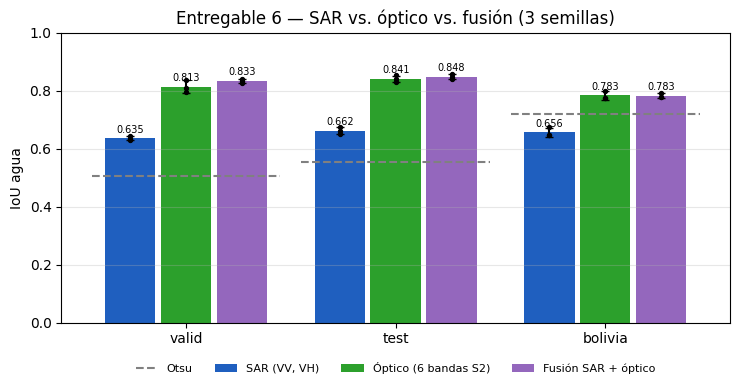

In [32]:
tabla_deltas = deltas_pareados(df_e6)
tabla_deltas.to_csv(DIR_RESULTADOS / 'f10_deltas.csv', index=False)
display(tabla_deltas)
figura_barras(df_e6, linea_otsu=LINEA_OTSU, ruta_guardado=DIR_FIGURAS / 'f10_barras_iou.png');

## 9. ¿Dónde ayuda la fusión? IoU por evento en test
Esperado según la fase 9: más ganancia en eventos con agua no especular o suelo árido oscuro (Pakistán, Somalia).

In [33]:
tabla_eventos = por_evento(DIR_EXPERIMENTOS, SEMILLAS, 'test')
tabla_eventos.to_csv(DIR_RESULTADOS / 'f10_por_evento_test.csv')
tabla_eventos.round(3)

,sar,optico,sar_optico,Δ fusión − sar
Pakistan,0.190,0.835,0.778,0.587
Somalia,0.500,0.779,0.820,0.321
USA,0.529,0.775,0.800,0.271
India,0.716,0.887,0.898,0.181
Paraguay,0.591,0.715,0.754,0.163
Spain,0.722,0.838,0.840,0.118
Mekong,0.852,0.926,0.938,0.085
Nigeria,0.881,0.936,0.942,0.061
Sri-Lanka,0.873,0.920,0.934,0.061
Ghana,0.532,0.566,0.553,0.021


## 10. Comparación visual: casos del entregable 5 + chip de test donde más gana la fusión
Semilla 42. Columnas: VH, S2 en color real, errores del SAR y errores de la fusión.

Chips de test con más ganancia de la fusión (IoU):


India_631692        0.869
Nigeria_225131      0.707
India_772630        0.678
Sri-Lanka_450918    0.636
Pakistan_849790     0.618
dtype: float64

Chips de test con MENOR ganancia (negativo = la fusión empeora):


Ghana_866994      -0.094
Paraguay_913449   -0.145
Nigeria_417184    -0.155
dtype: float64

En la figura: [('Pakistan_849790', 'test'), ('Pakistan_70625', 'test'), ('Bolivia_314919', 'bolivia'), ('India_631692', 'test')]


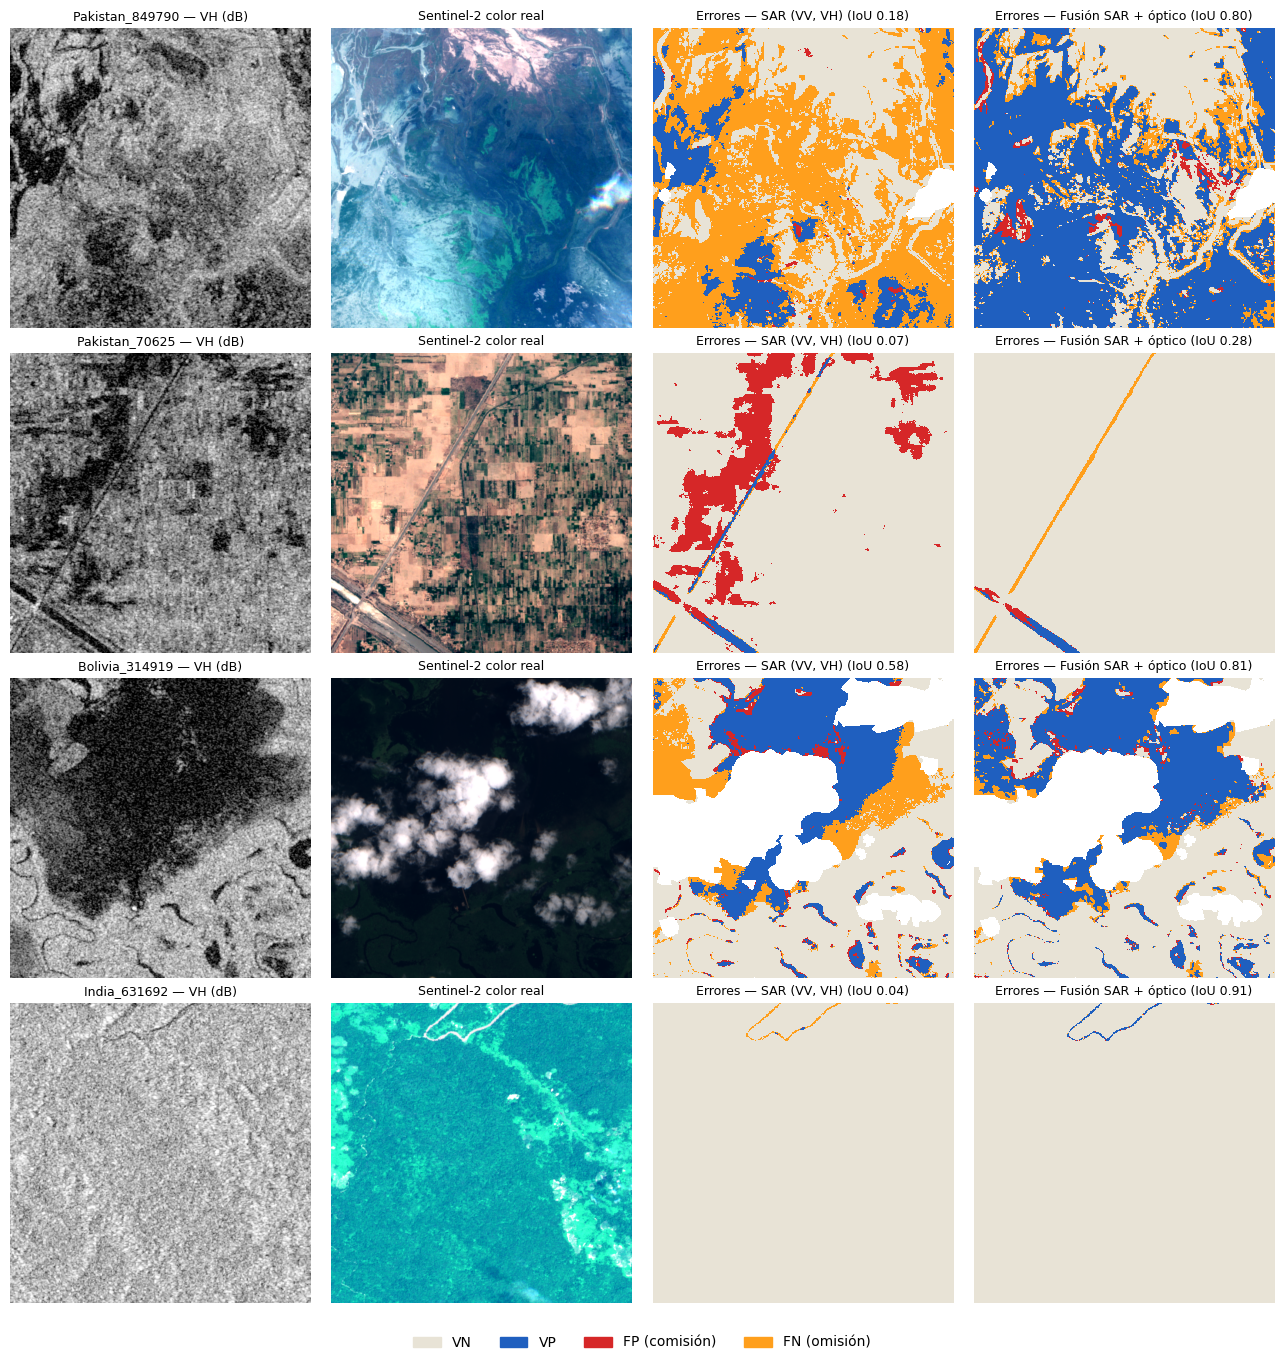

In [34]:
from src.comparacion_fusion import predecir_chips, iou_chip, ejemplos_para_figura
from src.lectura import leer_todas_las_particiones
dispositivo = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
normalizador_s2 = NormalizadorS2.desde_json(DIR_RESULTADOS / 'f10_estadisticas_s2.json')
particion_de = leer_todas_las_particiones().set_index('id_chip')['particion']

ids_test = leer_particion('test')['id_chip'].tolist()
CASOS_E5 = ['Pakistan_849790', 'Pakistan_70625', 'Bolivia_314919']
ids_figura = [i for i in CASOS_E5 if particion_de.get(i) in ('valid', 'test', 'bolivia')]
ids_todos = list(dict.fromkeys(ids_test + ids_figura))
predicciones = {m: predecir_chips(ids_todos, m, 42, normalizador, normalizador_s2, DIR_EXPERIMENTOS, dispositivo)
                for m in ['sar', 'sar_optico']}

ganancia = {i: iou_chip(*predicciones['sar_optico'][i]) - iou_chip(*predicciones['sar'][i]) for i in ids_test}
ganancia = pd.Series(ganancia).dropna().sort_values(ascending=False)
print('Chips de test con más ganancia de la fusión (IoU):'); display(ganancia.head(5).round(3))
print('Chips de test con MENOR ganancia (negativo = la fusión empeora):'); display(ganancia.tail(3).round(3))
ids_figura += [i for i in ganancia.index if i not in ids_figura][:1]   # el de más ganancia fuera de los casos E5
print('En la figura:', [(i, particion_de[i]) for i in ids_figura])
figura_comparacion(ejemplos_para_figura(ids_figura, predicciones), DIR_FIGURAS / 'f10_comparacion_casos.png');

## 11. Empaquetar resultados (sin pesos de los modelos, para que pese poco)

In [35]:
!cd /kaggle/working && zip -rq fase10.zip rnap_p2_inundaciones/resultados/f10_* rnap_p2_inundaciones/resultados/logs_e6 rnap_p2_inundaciones/figuras/f10_* rnap_p2_inundaciones/resultados/experimentos -x '*.pt'
!cd /kaggle/working && zip -rq fase10_pesos.zip rnap_p2_inundaciones/resultados/experimentos -i '*mejor.pt'
!ls -lh /kaggle/working/*.zip
from IPython.display import FileLink, display as mostrar
mostrar(FileLink('fase10.zip')); mostrar(FileLink('fase10_pesos.zip'))

-rw-r--r-- 1 root root 248M Oct 23 15:57 /kaggle/working/fase10_pesos.zip
-rw-r--r-- 1 root root 3.4M Oct 23 15:57 /kaggle/working/fase10.zip


/kaggle/working/fase10.zip

/kaggle/working/fase10_pesos.zip

## Para traer a la conversación
Salidas de las secciones **4** (forma/tipo + tabla de nubes), **7**, **8** (deltas + figura), **9** y **10** (ganancias + figura).